# Adversarial validation of the synthetic posts

`adversarial_validation.ipynb` showed that XLM-R separates the training sentences from the test posts
almost perfectly (AUC 0.99 on raw text, 0.97 with format and length hidden). We generated synthetic
posts to close that gap (`synthetic_data.ipynb`). Here we ask the same classifier two questions:

- **A.** Are the synthetic posts harder to tell from the test posts than the training sentences? Both
  are compared with the same split rules, sample sizes, model and settings.
- **B.** Which synthetic posts look least like test posts? Every synthetic post gets an out-of-fold
  score, which we can later use to filter or weight the training data (the instructor suggested
  filtering the synthetic data with an adversarial model trained against test).

The classifier is the one from the main task, `xlm-roberta-base` with a classification head, trained by
`evaluation/domain_classifier.py` with the settings of the earlier notebook: learning rate 2e-5, 2 epochs,
batch size 16, seed 42. Label 1 is always a test post, so a high score means "looks like test".

**Running it.** On Colab (GPU, about 20 minutes on an L4) it reads `bundle.zip` from the Drive folder
`dl-a4-synthetic` and writes the scores back to `dl-a4-synthetic/output`. Locally it runs from the
`synthetic/` folder of the repo.

In [1]:
import os
import subprocess
import sys
from pathlib import Path

if "google.colab" in sys.modules:
    from google.colab import drive

    drive.mount("/content/drive")
    DRIVE = Path("/content/drive/MyDrive/dl-a4-synthetic")
    REPO = Path("/content/a4")
    subprocess.run(["unzip", "-oq", str(DRIVE / "bundle.zip"), "-d", str(REPO)], check=True)
    SAVE = DRIVE / "output"
else:
    REPO = Path.cwd().parent
    SAVE = REPO / "synthetic" / "output"
SAVE.mkdir(parents=True, exist_ok=True)
os.chdir(REPO / "synthetic")
sys.path[:0] = [str(REPO), str(REPO / "synthetic")]

Mounted at /content/drive


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold
from transformers import AutoTokenizer

import synth_data as sd
from evaluation.domain_classifier import ClassifierConfig, mask_and_keep_long, train_and_score

MODEL = "FacebookAI/xlm-roberta-base"
SEED = 42
RAW_TOKENS, MASKED_TOKENS = 256, 32
tokenizer = AutoTokenizer.from_pretrained(MODEL)
config = ClassifierConfig(model=MODEL, seed=SEED, eval_batch_size=64)
pd.set_option("display.max_colwidth", 140)

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

## Data

Three kinds of text, each with a group id so that near-copies never end up on both sides of a split:
test posts (repost groups from `pseudo_labeling.ipynb`), training sentences (`group_id` from the CV
folds) and the clean synthetic posts (repost groups from `synthetic_data.ipynb`).

In [3]:
test = pd.read_parquet(REPO / "pseudo_label" / "output" / "test_pseudo.parquet")
test = pd.DataFrame({"text": test.text, "group": "test:" + test.group.astype(str), "half": test.seed_half})

syn = pd.read_parquet(REPO / "synthetic" / "output" / "full1_clean.parquet")
syn = syn.assign(group="syn:" + syn.duplicate_group.astype(str))

cv = pd.read_parquet(REPO / "data" / "cv_rows.parquet")
print(f"test posts: {len(test)}, synthetic posts: {len(syn)}, training sentences: {len(cv)}")

test posts: 477, synthetic posts: 5839, training sentences: 63388


## A. Training sentences against synthetic posts

Same recipe as `adversarial_validation.ipynb`: twice as many source texts as test posts, 90% Ukrainian
and 10% Russian, one text per group. Unlike the first notebook, the 80/20 split now keeps groups together
(one fold of a 5-fold `StratifiedGroupKFold`), so reposts of one test post can't be on both sides. Both
arms use the same test posts in the same fit and held-out parts, so the only difference is the source.

In [4]:
N_SOURCE = 2 * len(test)
N_UK = round(0.9 * N_SOURCE)


def one_per_group(frame, lang_col, lang, n):
    rows = frame[frame[lang_col] == lang].drop_duplicates("group").drop_duplicates("text")
    return rows.sample(n, random_state=SEED)


sentences = pd.concat([
    one_per_group(cv.assign(group="cv:" + cv.group_id), "source", "uk", N_UK),
    one_per_group(cv.assign(group="cv:" + cv.group_id), "source", "ru", N_SOURCE - N_UK),
])
synthetic = pd.concat([
    one_per_group(syn, "lang", "uk", N_UK),
    one_per_group(syn, "lang", "ru", N_SOURCE - N_UK),
])

# one split of the test posts, shared by both arms
test_fold = np.zeros(len(test), dtype=int)
for k, (_, idx) in enumerate(StratifiedGroupKFold(5, shuffle=True, random_state=SEED).split(test, test.half, test.group)):
    test_fold[idx] = k
test_holdout = test_fold == 0


def make_split(source):
    """Fit and held-out parts: source texts split by group 80/20, test posts by the shared split."""
    src_fold = np.zeros(len(source), dtype=int)
    groups = source.group.unique()
    rng = np.random.default_rng(SEED)
    held_groups = set(rng.choice(groups, size=len(groups) // 5, replace=False))
    src_hold = source.group.isin(held_groups).to_numpy()
    part = lambda frame, label: pd.DataFrame({"text": frame.text.to_numpy(), "label": label, "half": frame.get("half", pd.Series("", index=frame.index)).to_numpy()})
    fit = pd.concat([part(source[~src_hold], 0), part(test[~test_holdout], 1)], ignore_index=True)
    holdout = pd.concat([part(source[src_hold], 0), part(test[test_holdout], 1)], ignore_index=True)
    assert not set(fit.text) & set(holdout.text)
    return fit, holdout


splits = {"training sentences": make_split(sentences), "synthetic posts": make_split(synthetic)}
pd.DataFrame({name: {"fit": len(f), "held out": len(h), "held-out test posts": h.label.sum()} for name, (f, h) in splits.items()})

,training sentences,synthetic posts
fit,1141,1141
held out,290,290
held-out test posts,100,100


Two runs for each source. Run 1 sees the raw text, cut to 256 tokens. Run 2 hides format and length:
links, emoji and line breaks become spaces, texts shorter than 32 tokens are dropped and the rest are cut
to exactly 32 tokens.

In [5]:
def controlled(frame):
    return mask_and_keep_long(frame, tokenizer, MASKED_TOKENS)


results, holdout_scores = [], {}
for name, (fit, holdout) in splits.items():
    for run, prep, length in [("raw, 256 tokens", lambda f: f, RAW_TOKENS), ("masked, exactly 32 tokens", controlled, MASKED_TOKENS)]:
        f, h = prep(fit), prep(holdout)
        out = train_and_score(f"{name}-{run}".replace(" ", "_"), f, h, length, tokenizer=tokenizer, config=config)
        holdout_scores[(name, run)] = h.assign(score=out["scores"])
        results.append({"source": name, "run": run, "held out": len(h), "AUC": out["auc"]})

pd.DataFrame(results).pivot(index="run", columns="source", values="AUC").round(3)

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.weight  | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


{'loss': '0.6583', 'grad_norm': '5.055', 'learning_rate': '1.875e-05', 'epoch': '0.1389'}
{'loss': '0.552', 'grad_norm': '16.04', 'learning_rate': '1.736e-05', 'epoch': '0.2778'}
{'loss': '0.5124', 'grad_norm': '12.82', 'learning_rate': '1.597e-05', 'epoch': '0.4167'}
{'loss': '0.4311', 'grad_norm': '16.33', 'learning_rate': '1.458e-05', 'epoch': '0.5556'}
{'loss': '0.3666', 'grad_norm': '6.47', 'learning_rate': '1.319e-05', 'epoch': '0.6944'}
{'loss': '0.2203', 'grad_norm': '4.028', 'learning_rate': '1.181e-05', 'epoch': '0.8333'}
{'loss': '0.1316', 'grad_norm': '1.782', 'learning_rate': '1.042e-05', 'epoch': '0.9722'}
{'loss': '0.1679', 'grad_norm': '16.98', 'learning_rate': '9.028e-06', 'epoch': '1.111'}
{'loss': '0.1115', 'grad_norm': '2.467', 'learning_rate': '7.639e-06', 'epoch': '1.25'}
{'loss': '0.07878', 'grad_norm': '2.718', 'learning_rate': '6.25e-06', 'epoch': '1.389'}
{'loss': '0.05732', 'grad_norm': '0.7238', 'learning_rate': '4.861e-06', 'epoch': '1.528'}
{'loss': '0.124

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (637 > 512). Running this sequence through the model will result in indexing errors


... (6 outputs left out)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.weight  | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


{'loss': '0.6279', 'grad_norm': '5.585', 'learning_rate': '1.852e-05', 'epoch': '0.1639'}
{'loss': '0.6105', 'grad_norm': '4.33', 'learning_rate': '1.689e-05', 'epoch': '0.3279'}
{'loss': '0.5945', 'grad_norm': '3.542', 'learning_rate': '1.525e-05', 'epoch': '0.4918'}
{'loss': '0.6577', 'grad_norm': '3.803', 'learning_rate': '1.361e-05', 'epoch': '0.6557'}
{'loss': '0.6746', 'grad_norm': '7.669', 'learning_rate': '1.197e-05', 'epoch': '0.8197'}
{'loss': '0.574', 'grad_norm': '4.328', 'learning_rate': '1.033e-05', 'epoch': '0.9836'}
{'loss': '0.4823', 'grad_norm': '5.841', 'learning_rate': '8.689e-06', 'epoch': '1.148'}
{'loss': '0.5591', 'grad_norm': '7.441', 'learning_rate': '7.049e-06', 'epoch': '1.311'}
{'loss': '0.5437', 'grad_norm': '4.832', 'learning_rate': '5.41e-06', 'epoch': '1.475'}
{'loss': '0.5338', 'grad_norm': '6.559', 'learning_rate': '3.77e-06', 'epoch': '1.639'}
{'loss': '0.4768', 'grad_norm': '6.256', 'learning_rate': '2.131e-06', 'epoch': '1.803'}
{'loss': '0.5098', 

source,synthetic posts,training sentences
run,,
"masked, exactly 32 tokens",0.907,0.933
"raw, 256 tokens",0.941,0.989


For the synthetic arm we can also ask whether the generator mimics the posts it saw. It was given seed
half A as examples and never saw half B. If the classifier found it harder to separate synthetic posts
from half A than from half B, the synthetic data would fit the seeds rather than test posts in general.

In [6]:
rows = []
for run in ["raw, 256 tokens", "masked, exactly 32 tokens"]:
    h = holdout_scores[("synthetic posts", run)]
    for half in "AB":
        part = h[(h.label == 0) | (h.half == half)]
        rows.append({"run": run, "test half": half, "test posts": (part.label == 1).sum(), "AUC": roc_auc_score(part.label, part.score)})
pd.DataFrame(rows).pivot(index="run", columns="test half", values="AUC").round(3)

test half,A,B
run,,
"masked, exactly 32 tokens",0.891,0.926
"raw, 256 tokens",0.939,0.943


With about 45 held-out test posts per half, differences of a few hundredths are noise.

## B. Out-of-fold scores for every synthetic post

To filter the synthetic data, every post needs a score from a classifier that didn't train on it. We
split synthetic and test posts into 5 folds by group. For each fold we train on the other four folds and
score the held-out one. To keep the classes close to the part A ratio (and the run short), each
classifier trains on all the test posts of its four folds and three times as many synthetic posts
sampled from those folds. Only raw text is used here, since that is what the NER model will see.

Scores from different fold models are not on the same scale, so for filtering we use each post's
percentile among the synthetic posts of its own fold (1.0 = the most test-like).

In [7]:
K, RATIO = 5, 3
pool = pd.concat([
    pd.DataFrame({"text": syn.text, "label": 0, "group": syn.group, "syn_id": syn.syn_id}),
    pd.DataFrame({"text": test.text, "label": 1, "group": test.group, "syn_id": -1}),
], ignore_index=True)
pool["fold"] = -1
for k, (_, idx) in enumerate(StratifiedGroupKFold(K, shuffle=True, random_state=SEED).split(pool, pool.label, pool.group)):
    pool.loc[idx, "fold"] = k
pool["score"] = np.nan

fold_auc = []
for k in range(K):
    train_part, held = pool[pool.fold != k], pool[pool.fold == k]
    pos = train_part[train_part.label == 1]
    neg = train_part[train_part.label == 0].sample(RATIO * len(pos), random_state=SEED + k)
    fit = pd.concat([pos, neg])[["text", "label"]]
    out = train_and_score(f"oof_fold{k}", fit, held[["text", "label"]], RAW_TOKENS, tokenizer=tokenizer, config=config)
    pool.loc[held.index, "score"] = out["scores"]
    fold_auc.append({"fold": k, "fit": len(fit), "held-out synthetic": (held.label == 0).sum(), "held-out test": held.label.sum(), "AUC": out["auc"]})

fold_auc = pd.DataFrame(fold_auc)
print(f"out-of-fold AUC, mean of folds: {fold_auc.AUC.mean():.3f} (std {fold_auc.AUC.std():.3f})")
fold_auc.round(3)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.weight  | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


{'loss': '0.5695', 'grad_norm': '5.924', 'learning_rate': '1.905e-05', 'epoch': '0.1053'}
{'loss': '0.5443', 'grad_norm': '5.47', 'learning_rate': '1.8e-05', 'epoch': '0.2105'}
{'loss': '0.5482', 'grad_norm': '9.869', 'learning_rate': '1.695e-05', 'epoch': '0.3158'}
{'loss': '0.477', 'grad_norm': '4.86', 'learning_rate': '1.589e-05', 'epoch': '0.4211'}
{'loss': '0.5275', 'grad_norm': '4.623', 'learning_rate': '1.484e-05', 'epoch': '0.5263'}
{'loss': '0.4733', 'grad_norm': '5.118', 'learning_rate': '1.379e-05', 'epoch': '0.6316'}
{'loss': '0.4843', 'grad_norm': '9.044', 'learning_rate': '1.274e-05', 'epoch': '0.7368'}
{'loss': '0.3896', 'grad_norm': '10.13', 'learning_rate': '1.168e-05', 'epoch': '0.8421'}
{'loss': '0.4032', 'grad_norm': '6.695', 'learning_rate': '1.063e-05', 'epoch': '0.9474'}
{'loss': '0.3436', 'grad_norm': '8.419', 'learning_rate': '9.579e-06', 'epoch': '1.053'}
{'loss': '0.3026', 'grad_norm': '16.17', 'learning_rate': '8.526e-06', 'epoch': '1.158'}
{'loss': '0.225',

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.weight  | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


{'loss': '0.5669', 'grad_norm': '5.868', 'learning_rate': '1.906e-05', 'epoch': '0.1042'}
{'loss': '0.5344', 'grad_norm': '4.513', 'learning_rate': '1.802e-05', 'epoch': '0.2083'}
{'loss': '0.5238', 'grad_norm': '2.767', 'learning_rate': '1.698e-05', 'epoch': '0.3125'}
{'loss': '0.5358', 'grad_norm': '4.335', 'learning_rate': '1.594e-05', 'epoch': '0.4167'}
{'loss': '0.4489', 'grad_norm': '4.609', 'learning_rate': '1.49e-05', 'epoch': '0.5208'}
{'loss': '0.4149', 'grad_norm': '9.025', 'learning_rate': '1.385e-05', 'epoch': '0.625'}
{'loss': '0.4525', 'grad_norm': '3.258', 'learning_rate': '1.281e-05', 'epoch': '0.7292'}
{'loss': '0.4546', 'grad_norm': '6.813', 'learning_rate': '1.177e-05', 'epoch': '0.8333'}
{'loss': '0.3307', 'grad_norm': '8.836', 'learning_rate': '1.073e-05', 'epoch': '0.9375'}
{'loss': '0.3688', 'grad_norm': '23.82', 'learning_rate': '9.687e-06', 'epoch': '1.042'}
{'loss': '0.2615', 'grad_norm': '13', 'learning_rate': '8.646e-06', 'epoch': '1.146'}
{'loss': '0.3317'

... (6 outputs left out)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.weight  | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


{'loss': '0.6413', 'grad_norm': '2.373', 'learning_rate': '1.906e-05', 'epoch': '0.1042'}
{'loss': '0.5718', 'grad_norm': '3.174', 'learning_rate': '1.802e-05', 'epoch': '0.2083'}
{'loss': '0.5454', 'grad_norm': '5.277', 'learning_rate': '1.698e-05', 'epoch': '0.3125'}
{'loss': '0.5159', 'grad_norm': '6.001', 'learning_rate': '1.594e-05', 'epoch': '0.4167'}
{'loss': '0.4928', 'grad_norm': '9.004', 'learning_rate': '1.49e-05', 'epoch': '0.5208'}
{'loss': '0.4539', 'grad_norm': '9.497', 'learning_rate': '1.385e-05', 'epoch': '0.625'}
{'loss': '0.3564', 'grad_norm': '18.77', 'learning_rate': '1.281e-05', 'epoch': '0.7292'}
{'loss': '0.384', 'grad_norm': '6.003', 'learning_rate': '1.177e-05', 'epoch': '0.8333'}
{'loss': '0.295', 'grad_norm': '16.03', 'learning_rate': '1.073e-05', 'epoch': '0.9375'}
{'loss': '0.2466', 'grad_norm': '8.152', 'learning_rate': '9.687e-06', 'epoch': '1.042'}
{'loss': '0.2173', 'grad_norm': '5.75', 'learning_rate': '8.646e-06', 'epoch': '1.146'}
{'loss': '0.2167'

,fold,fit,held-out synthetic,held-out test,AUC
0,0,1516,1100,98,0.972
1,1,1528,1291,95,0.975
2,2,1524,1142,96,0.969
3,3,1532,1145,94,0.959
4,4,1532,1161,94,0.956


saved 5839 scores to /content/drive/MyDrive/dl-a4-synthetic/output/full1_adversarial.parquet


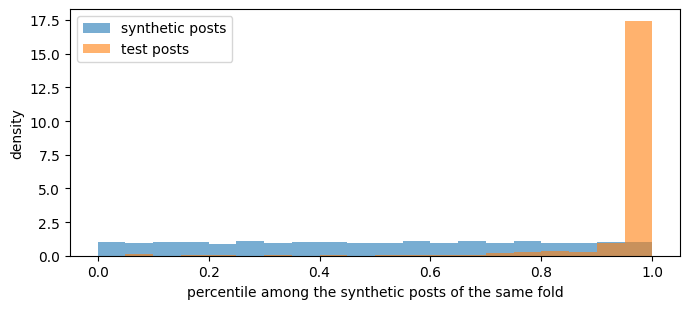

In [8]:
pool["test_like"] = pool[pool.label == 0].groupby("fold").score.rank(pct=True)
scores = syn[["syn_id", "text", "locations", "lang"]].merge(pool.loc[pool.label == 0, ["syn_id", "fold", "score", "test_like"]], on="syn_id")
scores[["syn_id", "fold", "score", "test_like"]].to_parquet(SAVE / "full1_adversarial.parquet", index=False)
print(f"saved {len(scores)} scores to {SAVE / 'full1_adversarial.parquet'}")

# test posts against the synthetic percentiles: the share of synthetic posts each test post outscores in its fold
syn_by_fold = {k: np.sort(g.score.to_numpy()) for k, g in pool[pool.label == 0].groupby("fold")}
test_pct = [np.searchsorted(syn_by_fold[f], s) / len(syn_by_fold[f]) for f, s in pool.loc[pool.label == 1, ["fold", "score"]].to_numpy()]

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(scores.test_like, bins=20, range=(0, 1), alpha=0.6, density=True, label="synthetic posts")
ax.hist(test_pct, bins=20, range=(0, 1), alpha=0.6, density=True, label="test posts")
ax.set_xlabel("percentile among the synthetic posts of the same fold")
ax.set_ylabel("density")
ax.legend()
plt.tight_layout()
plt.show()

Synthetic posts are uniform on this scale by construction. The test posts pile up on the right; the
synthetic posts that land in the same region are the ones the classifier confuses with test posts.

What gives a synthetic post away? We compare simple features across score quarters.

In [9]:
features = sd.style(scores).assign(
    places=scores.locations.str.len(),
    no_places=scores.locations.str.len() == 0,
    quarter=pd.cut(scores.test_like, [0, .25, .5, .75, 1], labels=["least test-like", "2", "3", "most test-like"]),
)
test_features = sd.style(test).assign(places=np.nan, no_places=np.nan)
summary = features.groupby("quarter", observed=True).agg(
    posts=("chars", "size"), chars_median=("chars", "median"), line_breaks=("has_line_break", "mean"),
    emoji=("has_emoji", "mean"), russian=("lang", lambda s: (s == "ru").mean()), places_mean=("places", "mean"),
    no_places=("no_places", "mean"),
)
summary.loc["test posts"] = [len(test), test_features.chars.median(), test_features.has_line_break.mean(), test_features.has_emoji.mean(), (test_features.lang == "ru").mean(), 1.5, 0.33]
summary.round(2)

,posts,chars_median,line_breaks,emoji,russian,places_mean,no_places
quarter,,,,,,,
least test-like,1456.0,312.0,0.82,0.68,0.08,1.48,0.36
2,1463.0,278.0,0.80,0.65,0.09,1.43,0.36
3,1451.0,280.0,0.79,0.65,0.09,1.34,0.40
most test-like,1469.0,227.0,0.75,0.66,0.10,1.27,0.43
test posts,477.0,264.0,0.85,0.60,0.07,1.50,0.33


The two ends of the scale:

In [10]:
def show(frame):
    return frame[["test_like", "text", "locations"]].assign(text=lambda d: d.text.str.slice(0, 160).str.replace("\n", " / "))


show(scores.nsmallest(6, "test_like"))

,test_like,text,locations
1861,0.000775,"❗️ У столиці зафіксували перші осінні заморозки на ґрунті / / Як повідомляють метеорологи, уночі температура на поверхні ґрунту опускал...",[]
3800,0.000861,"⚠️ Шановні мешканці! Вчора ввечері отримали кілька звернень щодо відключення гарячої води / / Як повідомили в диспетчерській, 14 будинк...",[]
4101,0.000873,Відкрився новий магазин мережі біля станції метро Либідська 💰 / / Це вже третя точка в Голосіївському районі. Керівництво мережі анонсу...,"[метро Либідська, Голосіївському районі, вулиці Васильківській, 15, метро Палац «Україна]"
2141,0.000876,⚠️Гідрологи попереджають про підйом води / / Через дощі рівень Дніпра зростає. Затоплення можливі у Оболонському районі та біля метро Г...,"[Дніпра, Оболонському районі, вулиця Оболонська, 3-15, вулиця Прирічна, метро Гідропарк]"
876,0.001364,"У Деснянському районі затримали 34-річного чоловіка, який намагався продати викрадений телефон. Правоохоронці задокументували факт шахра...",[Деснянському районі]
3691,0.001364,У Дарницькому районі відновили роботу центру надання адмінпослуг після ремонту,[Дарницькому районі]


In [11]:
show(scores.nlargest(6, "test_like"))

,test_like,text,locations
458,1.000000,"🇺🇦 ЗСУ просунулися на Бахмутському напрямку, — Генштаб.",[]
1906,1.000000,"Німеччина передає Україні новий пакет ПЗРК, – МЗС ФРН","[Німеччина, Україні]"
3562,1.000000,"Волонтёры из Ирпеня, Бучи и Вышгорода привезли помощь в сёла Мотовиловка и Тарасовка","[Ирпеня, Бучи, Вышгорода, Мотовиловка, Тарасовка]"
3756,1.000000,Бобри знову з'явилися на Володимирській гірці,[]
3940,1.000000,"Зникла собака породи коргі, відповідає на кличку Мокко. Телефон 0671234567 / / 📍Осокорки",[Осокорки]
5681,0.999225,Синай у суді продовжив арешт екс-депутата 🔒,[]


## Filter candidates

A threshold on `test_like` is a training hyperparameter, not something this notebook can decide. Each
cut makes the data more test-like but smaller, and the classifier only sees style, not label quality. We
save the scores and will compare a few cuts in the NER experiments by their score on seed half B, on the
26 labeled posts and on the leaderboard. To see what a cut would remove from the label distribution:

In [12]:
def label_profile(frame):
    strings = [s for row in frame.locations for s in row]
    top2 = sum(s in {"Деснянському районі", "Дарницькому районі"} for s in strings)
    return {
        "posts": len(frame),
        "Russian": f"{(frame.lang == 'ru').mean():.0%}",
        "no places": f"{(frame.locations.str.len() == 0).mean():.0%}",
        "places per post": round(frame.locations.str.len().mean(), 2),
        "distinct places": len(set(strings)),
        "Деснянському/Дарницькому районі share": f"{top2 / max(len(strings), 1):.1%}",
    }


pd.DataFrame({f"keep top {int(q * 100)}%": label_profile(scores[scores.test_like > 1 - q]) for q in [1.0, 0.75, 0.5, 0.25]})

,keep top 100%,keep top 75%,keep top 50%,keep top 25%
posts,5839,4383,2920,1469
Russian,9%,9%,9%,10%
no places,39%,40%,42%,43%
places per post,1.38,1.35,1.3,1.27
distinct places,2397,1914,1409,864
Деснянському/Дарницькому районі share,11.1%,10.3%,9.6%,7.8%


## Conclusions

**A. Synthetic posts are closer to test than the training sentences, but still easy to tell apart.**

| Run | Training sentences | Synthetic posts |
| --- | ---: | ---: |
| raw, 256 tokens | 0.989 | 0.941 |
| masked, exactly 32 tokens | 0.933 | 0.907 |

Both arms use the same 100 held-out test posts (290 held-out texts). The raw result for the sentences
repeats the 0.992 of `adversarial_validation.ipynb`. The masked one is lower than the earlier 0.972
because the split now keeps reposts together and the sample is different, so compare numbers only within
this table. On raw text the gap (0.05) is large for this sample size; on masked text (0.026) it is within
the noise of 100 test posts. So most of the gain is in format and length, which the mutators targeted, and
the content is still recognizably different.

**The generator doesn't mimic its seeds.** On raw text, synthetic posts are as easy to separate from
half A (seen by the generator, 0.939) as from half B (never seen, 0.943). The masked run is a little
harder on half A (0.891 against 0.926), but with about 50 test posts per half that is a weak hint at
most. This agrees with `synthetic_data.ipynb`: no copies of test posts and the same place coverage of
both halves.

**B. Out-of-fold, the classifier separates almost all synthetic posts** (fold AUC 0.956-0.975, mean
0.966; higher than in part A because each model trains on more texts). What gives a post away is being
too "complete": the least test-like quarter is longer (median 312 characters against 227 for the most
test-like quarter and 264 for test) and has more places (1.48 against 1.27), typically an official
announcement with a list of streets, house numbers and metro stations. The most test-like posts are short
headlines about the war or national news, lost-pet posts and short Russian posts, which is what many test
posts look like.

**Filtering has a price.** The classifier prefers short posts with few places, which carry the least NER
signal. Keeping the top 50% halves the data and cuts the distinct places from 2,397 to 1,409; the top 25%
leaves 864. It barely fixes the Деснянський/Дарницький skew (11.1% to 7.8% of place strings). So we don't
pick a threshold here. In NER training we compare all 5,839 posts, the top 75% and the top 50%, plus
sample weights from `test_like` as a softer option, and judge them on seed half B, the 26 labeled posts
and the leaderboard. The scores are in `output/full1_adversarial.parquet` (join on `syn_id`).
